       TRAFFIC IMAGE PROCESSING

Single image mode: Displaying traffic image dl.jpg


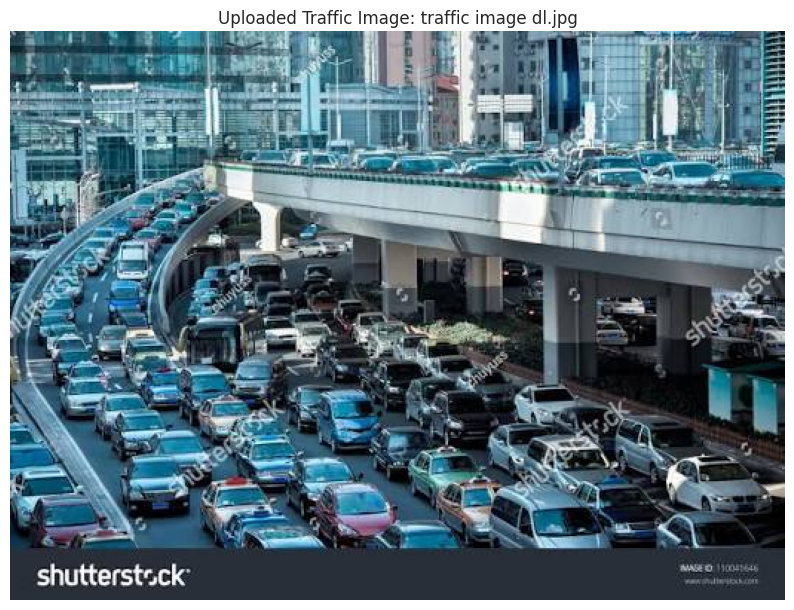

In [2]:
import os
import glob
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from collections import Counter
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
random.seed(42)

print("=" * 65)
print("       TRAFFIC IMAGE PROCESSING")
print("=" * 65)

# Check if an image is already uploaded or prompt for upload
uploaded_files = glob.glob("*.jpg") + glob.glob("*.png") + glob.glob("*.jpeg")

if not uploaded_files:
    print("\nPLEASE UPLOAD YOUR TRAFFIC IMAGE OR COCO ZIP FILE")
    uploaded = files.upload()
    uploaded_files = list(uploaded.keys())

zip_file = next((f for f in uploaded_files if f.lower().endswith(".zip")), None)
image_file = next((f for f in uploaded_files if f.lower().endswith(('.jpg', '.jpeg', '.png'))), None)

if zip_file:
    # 2. EXTRACT DATASET
    dataset_path = "/content/traffic_coco"
    os.makedirs(dataset_path, exist_ok=True)
    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall(dataset_path)
    print("\nDataset extracted successfully!")

    # FIND IMAGE AND LABEL FOLDERS
    image_files = glob.glob(dataset_path + "/**/images/**/*.jpg", recursive=True)
    if not image_files:
        image_files = glob.glob(dataset_path + "/**/*.jpg", recursive=True)
    label_files = glob.glob(dataset_path + "/**/labels/**/*.txt", recursive=True)

    if not image_files:
        raise FileNotFoundError("No images found in ZIP!")
    if not label_files:
        raise FileNotFoundError("No YOLO annotation files found!")

    label_lookup = {os.path.splitext(os.path.basename(p))[0]: p for p in label_files}
    print("Total photographs:", len(image_files))
    print("Total annotation files:", len(label_files))

    class_names = [
        "person", "bicycle", "car", "motorcycle", "airplane",
        "bus", "train", "truck", "boat", "traffic light",
        "fire hydrant", "stop sign", "parking meter", "bench",
        "bird", "cat", "dog", "horse", "sheep", "cow",
        "elephant", "bear", "zebra", "giraffe", "backpack",
        "umbrella", "handbag", "tie", "suitcase", "frisbee",
        "skis", "snowboard", "sports ball", "kite",
        "baseball bat", "baseball glove", "skateboard",
        "surfboard", "tennis racket", "bottle", "wine glass",
        "cup", "fork", "knife", "spoon", "bowl", "banana",
        "apple", "sandwich", "orange", "broccoli", "carrot",
        "hot dog", "pizza", "donut", "cake", "chair", "couch",
        "potted plant", "bed", "dining table", "toilet", "tv",
        "laptop", "mouse", "remote", "keyboard", "cell phone",
        "microwave", "oven", "toaster", "sink", "refrigerator",
        "book", "clock", "vase", "scissors", "teddy bear",
        "hair drier", "toothbrush"
    ]
    vehicle_ids = [1, 2, 3, 5, 7]
    road_ids = [9, 11, 12]

    traffic_records = []
    category_counts = Counter()

    for image_path in image_files:
        name = os.path.splitext(os.path.basename(image_path))[0]
        label_path = label_lookup.get(name)
        if not label_path: continue
        objects = []
        with open(label_path, "r") as f:
            lines = f.readlines()
        for line in lines:
            values = list(map(float, line.split()))
            if len(values) < 5: continue
            cid = int(values[0])
            if cid not in vehicle_ids + road_ids: continue
            xc, yc, w, h = values[1:5]
            objects.append({"id": cid, "name": class_names[cid], "xc": xc, "yc": yc, "w": w, "h": h})
        if any(obj["id"] in vehicle_ids for obj in objects):
            traffic_records.append({"path": image_path, "objects": objects})
            for obj in objects:
                category_counts[obj["name"]] += 1

    print("\nTRAFFIC IMAGES FOUND:", len(traffic_records))

    # Display multiple images with bounding boxes
    sample = random.sample(traffic_records, min(9, len(traffic_records)))
    fig, axes = plt.subplots(3, 3, figsize=(20, 15))
    axes = axes.flatten()
    for ax, record in zip(axes, sample):
        img = Image.open(record["path"]).convert("RGB")
        width, height = img.size
        ax.imshow(img)
        for obj in record["objects"]:
            xc = obj["xc"] * width
            yc = obj["yc"] * height
            bw = obj["w"] * width
            bh = obj["h"] * height
            x, y = xc - bw / 2, yc - bh / 2
            ax.add_patch(patches.Rectangle((x, y), bw, bh, linewidth=2, edgecolor="lime", facecolor="none"))
            ax.text(x, max(0, y - 5), obj["name"], color="white", fontsize=9, bbox=dict(facecolor="green", alpha=0.8))
        ax.set_title(os.path.basename(record["path"]), fontsize=10)
        ax.axis("off")
    for ax in axes[len(sample):]: ax.axis("off")
    plt.suptitle("REAL TRAFFIC IMAGES - VEHICLE DETECTION", fontsize=22, fontweight="bold")
    plt.tight_layout()
    plt.show()

elif image_file:
    print(f"\nSingle image mode: Displaying {image_file}")
    img = Image.open(image_file).convert("RGB")
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.title(f"Uploaded Traffic Image: {image_file}")
    plt.axis("off")
    plt.show()
else:
    raise ValueError("Please upload either a COCO ZIP file or a valid traffic image (.jpg, .png)!")